Shape: (3005, 12)

Missing Values:
Age                        150
Annual_Income_K            180
Visit_Frequency_Monthly    120
Avg_Transaction_Value       90
dtype: int64

Summary Statistics:
           Age  Annual_Income_K  Spending_Score  Visit_Frequency_Monthly  \
count  2855.00          2825.00         3005.00                  2885.00   
mean     37.92            57.45           44.07                     6.15   
std      13.85            29.57           22.88                     4.19   
min      18.00           -70.00            1.00                     1.00   
25%      26.00            35.00           27.00                     3.00   
50%      37.00            54.00           43.00                     5.00   
75%      48.00            76.00           61.00                     9.00   
max     121.00           150.00          100.00                    20.00   

       Avg_Transaction_Value  Years_as_Member  Distance_to_Store_Miles  \
count                2915.00          3005.00   

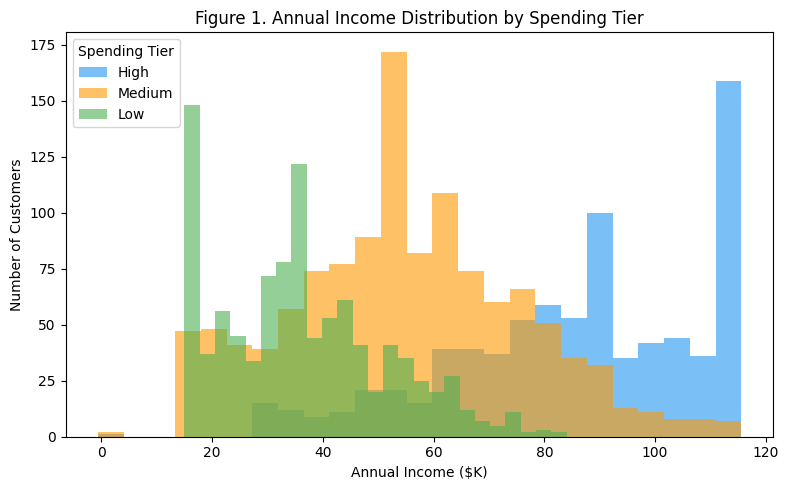

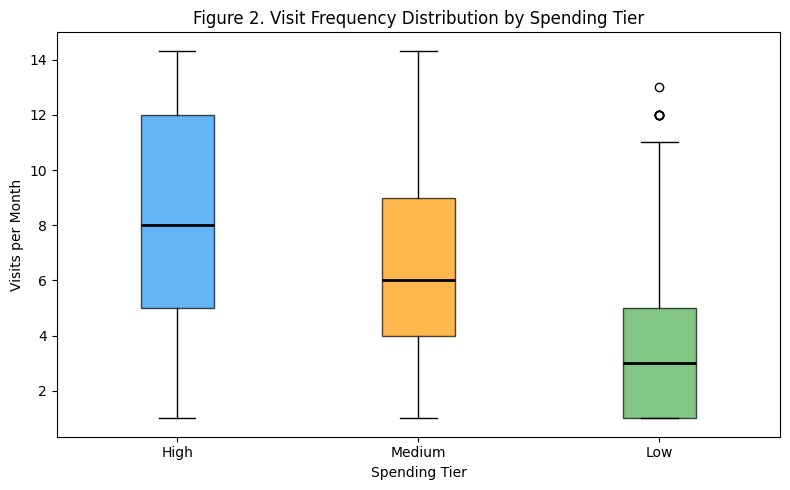

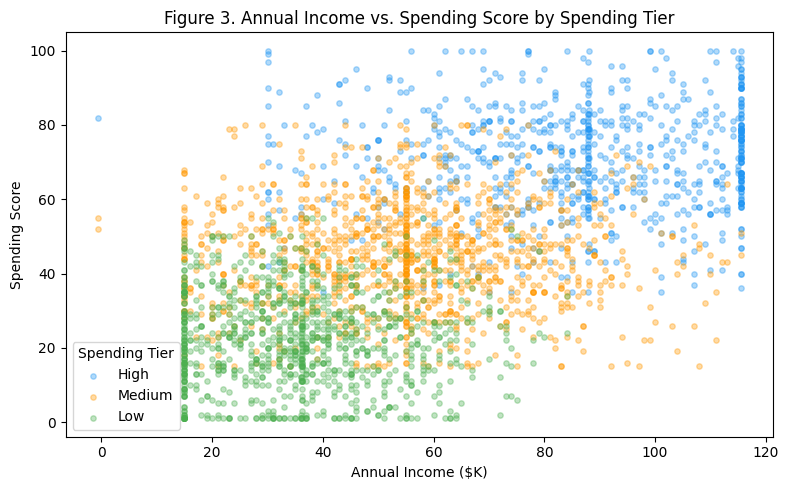


Train: 2402 | Test: 601

────────────────────────────────────────
K = 5 | Accuracy: 0.7105
────────────────────────────────────────
              precision    recall  f1-score   support

        High       0.74      0.66      0.70       160
      Medium       0.75      0.83      0.79       200
         Low       0.66      0.64      0.65       241

    accuracy                           0.71       601
   macro avg       0.71      0.71      0.71       601
weighted avg       0.71      0.71      0.71       601



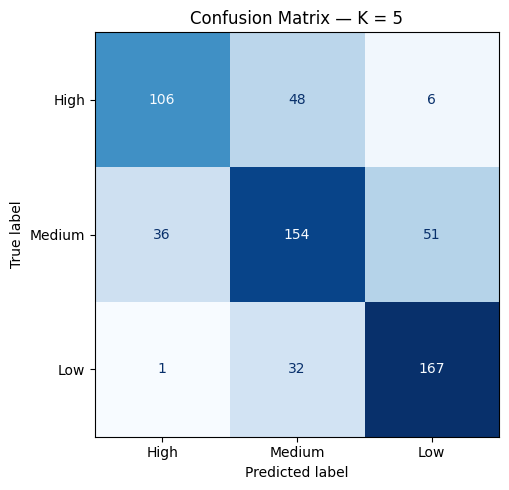


────────────────────────────────────────
K = 15 | Accuracy: 0.7155
────────────────────────────────────────
              precision    recall  f1-score   support

        High       0.76      0.69      0.72       160
      Medium       0.72      0.85      0.78       200
         Low       0.68      0.62      0.65       241

    accuracy                           0.72       601
   macro avg       0.72      0.72      0.72       601
weighted avg       0.71      0.72      0.71       601



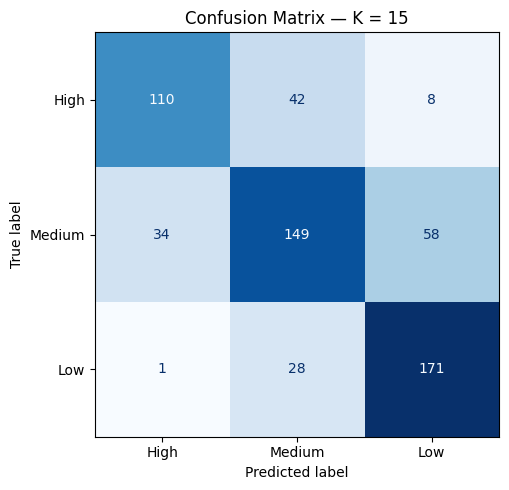


────────────────────────────────────────
K = 30 | Accuracy: 0.7238
────────────────────────────────────────
              precision    recall  f1-score   support

        High       0.77      0.69      0.73       160
      Medium       0.73      0.87      0.80       200
         Low       0.68      0.63      0.65       241

    accuracy                           0.72       601
   macro avg       0.73      0.73      0.73       601
weighted avg       0.72      0.72      0.72       601



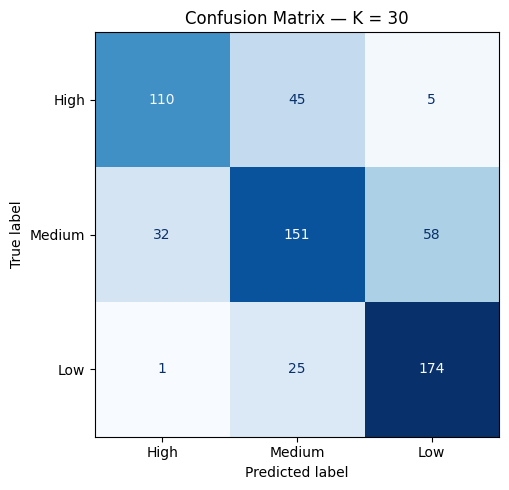


Model Comparison:
         Accuracy  Precision  Recall  F1-Score
K Value                                       
5          0.7105     0.7093  0.7105    0.7084
15         0.7155     0.7149  0.7155    0.7122
30         0.7238     0.7231  0.7238    0.7204


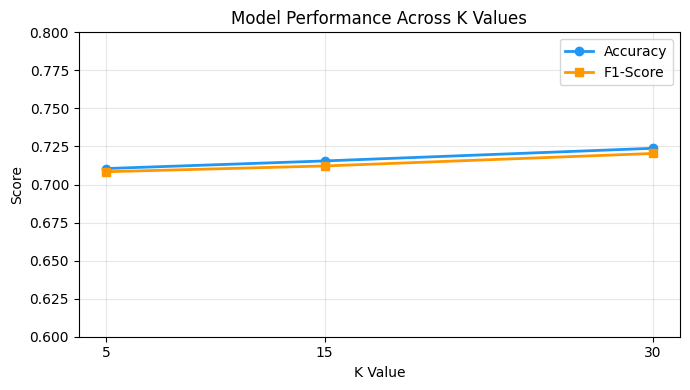

In [1]:
# ALY 6020 | Week 1 | Customer Segmentation with KNN | Lakeview Mall

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import warnings
warnings.filterwarnings('ignore')

# =============================================================================
# 1. LOAD & INSPECT
# =============================================================================

df = pd.read_csv('mall_customers.csv')
print(f"Shape: {df.shape}")
print(f"\nMissing Values:\n{df.isnull().sum()[df.isnull().sum() > 0]}")
print(f"\nSummary Statistics:\n{df.describe().round(2)}")

# =============================================================================
# 2. DATA CLEANING
# =============================================================================

df_clean = df.copy()

# --- Drop non-informative column ---
df_clean.drop(columns=['CustomerID'], inplace=True)

# --- Fix data types ---
df_clean['Gender']             = df_clean['Gender'].astype('category')
df_clean['Preferred_Category'] = df_clean['Preferred_Category'].astype('category')
df_clean['Spending_Tier']      = df_clean['Spending_Tier'].astype('category')

# --- Duplicates ---
dupes = df_clean.duplicated().sum()
df_clean.drop_duplicates(inplace=True)
print(f"\nDuplicates removed: {dupes} | New shape: {df_clean.shape}")

# --- Impossible values (flagged before capping) ---
print(f"\nImpossible Values:")
print(f"  Age > 100          : {(df_clean['Age'] > 100).sum()} records")
print(f"  Annual_Income_K < 0: {(df_clean['Annual_Income_K'] < 0).sum()} records")

# --- Missing value treatment ---
# Age (5.0%, skew=0.53) → group-by Spending_Tier mean
df_clean['Age'] = df_clean['Age'].fillna(
    df_clean.groupby('Spending_Tier')['Age'].transform('mean'))

# Annual_Income_K (6.0%, skew=0.59) → group-by Spending_Tier mean
df_clean['Annual_Income_K'] = df_clean['Annual_Income_K'].fillna(
    df_clean.groupby('Spending_Tier')['Annual_Income_K'].transform('mean'))

# Visit_Frequency_Monthly (4.0%, skew=0.68) → median
df_clean['Visit_Frequency_Monthly'] = df_clean['Visit_Frequency_Monthly'].fillna(
    df_clean['Visit_Frequency_Monthly'].median())

# Avg_Transaction_Value (3.0%, skew=7.88) → median
df_clean['Avg_Transaction_Value'] = df_clean['Avg_Transaction_Value'].fillna(
    df_clean['Avg_Transaction_Value'].median())

df_clean['Age'] = df_clean['Age'].round().astype(int)

# --- Outlier capping (±2 std dev) ---
# Spending_Score NOT capped — bounded 1–100 scale by design
cols_to_cap = ['Age', 'Annual_Income_K', 'Visit_Frequency_Monthly', 'Avg_Transaction_Value']
print(f"\n{'Column':<30} {'Outliers':>8}  {'Range After Capping'}")
print("-" * 60)
for col in cols_to_cap:
    mean, std = df_clean[col].mean(), df_clean[col].std()
    lower, upper = mean - 2*std, mean + 2*std
    n = ((df_clean[col] > upper) | (df_clean[col] < lower)).sum()
    df_clean[col] = df_clean[col].clip(lower, upper)
    print(f"{col:<30} {n:>8}  [{lower:.1f}, {upper:.1f}]")

# =============================================================================
# 3. EXPLORATORY DATA ANALYSIS
# =============================================================================

tier_order  = ['High', 'Medium', 'Low']
tier_colors = {'High': '#2196F3', 'Medium': '#FF9800', 'Low': '#4CAF50'}

print(f"\nMean Values by Spending Tier:")
print(df_clean.groupby('Spending_Tier')[
    ['Annual_Income_K', 'Visit_Frequency_Monthly', 'Age', 'Spending_Score']
].mean().round(2).to_string())

# Figure 1: Income Distribution by Tier
fig, ax = plt.subplots(figsize=(8, 5))
for tier in tier_order:
    ax.hist(df_clean[df_clean['Spending_Tier'] == tier]['Annual_Income_K'],
            bins=25, alpha=0.6, label=tier, color=tier_colors[tier])
ax.set_xlabel('Annual Income ($K)')
ax.set_ylabel('Number of Customers')
ax.set_title('Figure 1. Annual Income Distribution by Spending Tier')
ax.legend(title='Spending Tier')
plt.tight_layout()
plt.savefig('fig1_income_by_tier.png', dpi=150, bbox_inches='tight')
plt.show()

# Figure 2: Visit Frequency Boxplot by Tier
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot(
    [df_clean[df_clean['Spending_Tier'] == t]['Visit_Frequency_Monthly'].values
     for t in tier_order],
    labels=tier_order, patch_artist=True,
    medianprops=dict(color='black', linewidth=2))
for patch, tier in zip(bp['boxes'], tier_order):
    patch.set_facecolor(tier_colors[tier])
    patch.set_alpha(0.7)
ax.set_xlabel('Spending Tier')
ax.set_ylabel('Visits per Month')
ax.set_title('Figure 2. Visit Frequency Distribution by Spending Tier')
plt.tight_layout()
plt.savefig('fig2_visits_by_tier.png', dpi=150, bbox_inches='tight')
plt.show()

# Figure 3: Income vs Spending Score by Tier
fig, ax = plt.subplots(figsize=(8, 5))
for tier in tier_order:
    s = df_clean[df_clean['Spending_Tier'] == tier]
    ax.scatter(s['Annual_Income_K'], s['Spending_Score'],
               alpha=0.35, label=tier, color=tier_colors[tier], s=15)
ax.set_xlabel('Annual Income ($K)')
ax.set_ylabel('Spending Score')
ax.set_title('Figure 3. Annual Income vs. Spending Score by Spending Tier')
ax.legend(title='Spending Tier')
plt.tight_layout()
plt.savefig('fig3_income_vs_score.png', dpi=150, bbox_inches='tight')
plt.show()

# =============================================================================
# 4. FEATURE SCALING & TRAIN-TEST SPLIT
# =============================================================================

features = ['Annual_Income_K', 'Visit_Frequency_Monthly', 'Age']
X = df_clean[features]
y = df_clean['Spending_Tier']

X_scaled = StandardScaler().fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTrain: {len(X_train)} | Test: {len(X_test)}")

# =============================================================================
# 5. KNN MODELS — K = 5, 15, 30
# =============================================================================

results = {}

for k in [5, 15, 30]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)

    acc    = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred,
                                   target_names=['High', 'Medium', 'Low'],
                                   output_dict=True)

    print(f"\n{'─'*40}\nK = {k} | Accuracy: {acc:.4f}\n{'─'*40}")
    print(classification_report(y_test, y_pred, target_names=['High', 'Medium', 'Low']))

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, y_pred, labels=['High', 'Medium', 'Low']),
        display_labels=['High', 'Medium', 'Low']
    ).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Confusion Matrix — K = {k}')
    plt.tight_layout()
    plt.savefig(f'fig_cm_k{k}.png', dpi=150, bbox_inches='tight')
    plt.show()

    results[k] = {
        'Accuracy'     : round(acc, 4),
        'Precision'    : round(report['weighted avg']['precision'], 4),
        'Recall'       : round(report['weighted avg']['recall'], 4),
        'F1-Score'     : round(report['weighted avg']['f1-score'], 4),
    }

# =============================================================================
# 6. MODEL COMPARISON
# =============================================================================

results_df = pd.DataFrame(results).T
results_df.index.name = 'K Value'
print(f"\nModel Comparison:\n{results_df.to_string()}")

fig, ax = plt.subplots(figsize=(7, 4))
k_vals = list(results.keys())
ax.plot(k_vals, [results[k]['Accuracy'] for k in k_vals],
        marker='o', label='Accuracy', linewidth=2, color='#2196F3')
ax.plot(k_vals, [results[k]['F1-Score'] for k in k_vals],
        marker='s', label='F1-Score', linewidth=2, color='#FF9800')
ax.set_xlabel('K Value')
ax.set_ylabel('Score')
ax.set_title('Model Performance Across K Values')
ax.set_xticks(k_vals)
ax.set_ylim(0.60, 0.80)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()